In [1]:
import arcpy
import os
from pathlib import Path

In [2]:
os.getcwd()

'C:\\Users\\brian\\Documents\\2026-2027\\Fall 2026\\Spatial Programming\\Week 7 lab'

In [3]:
arcpy.env.workspace = os.getcwd()
"""In the current working directory, I will also have folders containing data for (1) Airports in Maine and Main counties and (2) NLCD data for Maine.
When importing a shapefile or a raster file, I will add the name of the folder containing the file into the file name."""
arcpy.env.overwriteOutput = True
arcpy.CheckOutExtension("Spatial")

'CheckedOut'

# Question 2
Reading in the airports and counties shapefiles and creating feature layers out of them

In [4]:
arcpy.management.MakeFeatureLayer(r"\Maine_County_Airports\maine_airports.shp", "Maine Airports")
arcpy.management.MakeFeatureLayer(r"\Maine_County_Airports\maine_county.shp", "Maine County")

<Result 'Maine County'>

I'm going to look at the individual features within the "Maine Counties" layer

In [5]:
# countyLayerFields = arcpy.ListFields(r"\Maine_County_Airports\maine_airports.shp")
countyLayerFields = arcpy.ListFields("Maine County")
countyLayerFieldsList = []
for field in countyLayerFields:
    countyLayerFieldsList.append(field.name)

In [6]:
countyLayerSearchCursor = arcpy.SearchCursor("Maine County")
for row in countyLayerSearchCursor:
    for field in countyLayerFieldsList:
        print(row.getValue(field))

0
<geoprocessing describe geometry object object at 0x000002D31B081980>
23
Maine
003
Aroostook
17683.29342207
8.18214738898
2.07840152942


So the Maine County layer only contains Aroostook county and no other counties. Going to clip the airports layer to only include airports in Aroostook county, now.

In [7]:
arcpy.analysis.Clip("Maine Airports", "Maine County", r"\Maine_County_Airports\Aroostook County airports.shp")

<Result 'C:\\Users\\brian\\Documents\\2026-2027\\Fall 2026\\Spatial Programming\\Week 7 lab\\\\Maine_County_Airports\\Aroostook County airports.shp'>

# Question 3

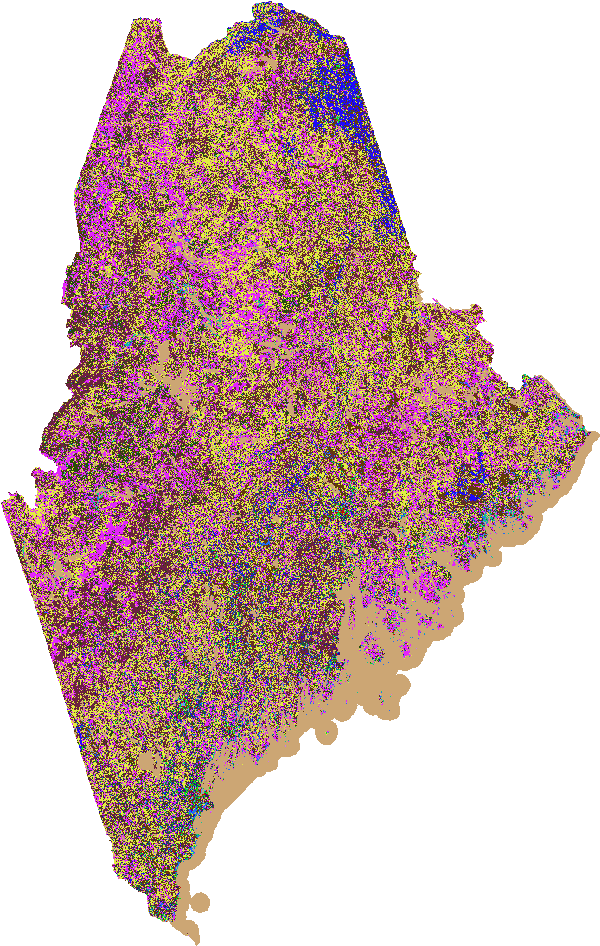

In [12]:
landCoverData = arcpy.sa.Raster(r"\nlcd_2011\nlcd_2011")
landCoverData

In [15]:
"""As you can see above, the dataset does exist. However, if I try to clip it"""
arcpy.management.Clip(landCoverData, out_raster="AroostookCountyLandCover.tif", in_template_dataset="Maine County", clipping_geometry=True)
"""I honestly have no clue why there's an error message saying that the dataset doesn't exist or isn't supported"""

"I honestly have no clue why there's an error message saying that the dataset doesn't exist or isn't supported"

In [16]:
"""And if I tried to use a different method e.g. extract by mask, I run into the same problem of the land cover
dataset somehow not existing"""
aroostookLandCover = arcpy.sa.ExtractByMask(landCoverData, "Maine County", "INSIDE")

I can't clip the land cover data because of these errors, so I'll just move on

# Question 4

In [11]:
maineFolder = Path(os.getcwd())/"Maine_County_Airports"
maineContents = os.listdir(maineFolder)
maineShapefiles1 = []
for file in maineContents:
    if file.endswith(".shp"):
        maineShapefiles1.append(file)

In [12]:
arcpy.env.workspace = os.getcwd() + "\\Maine_County_Airports"
maineContents2 = arcpy.ListFiles()
maineShapefiles2 = arcpy.ListFeatureClasses()